# Pregunta 3 — Entrega, flete y satisfacción

**Autor:** Gustavo Bazalar  
**Caso integrador:** Analytics Essentials I · Avance 1 · R

**Pregunta:** ¿Qué relación existe entre demora de entrega, flete, valor de compra y calificación?

El objetivo es identificar qué señales merecen revisión por Operaciones y Servicio al Cliente.
Trabajamos con una fila por pedido y conservamos la ventana de la Pregunta 1 del equipo:
compras de enero de 2017 a agosto de 2018 que figuran como entregadas.
Las relaciones se interpretan como asociaciones descriptivas.

Este aporte amplía el análisis del equipo con indicadores de entrega, correlaciones de Spearman,
comparaciones por tramos y dos gráficos en ggplot2. La agregación de ítems y reseñas sigue el criterio
de `Pregunta1.ipynb`: sumar los importes y promediar las reseñas de cada pedido antes de unir.


## Cómo ejecutar

1. En el repositorio, coloca este archivo dentro de `notebooks/` y los CSV originales en `data/olist/`.
2. También funciona con el ZIP original: en Google Colab con entorno **R**, sube `KAGGLE.zip`
   al panel de archivos antes de ejecutar. El código extrae únicamente las tres tablas necesarias.
3. Ejecuta todas las celdas en orden. La primera instala las bibliotecas que falten.
4. Las tablas de resultados y los gráficos se guardan en `salidas/pregunta3_gustavo/`.

No se necesita editar valores de resultados: las tablas, conclusiones y gráficos se calculan al ejecutar.
Si existen varios ZIP de Olist, indica cuál usar en `ruta_zip_manual`.


## 1. Entorno de trabajo

Usamos los mismos paquetes de preparación y visualización que en el avance del equipo.
`stringr` estandariza los estados; `lubridate` interpreta fechas; una función propia y `purrr`
automatizan las comparaciones y correlaciones.


In [1]:
paquetes <- c("readr", "dplyr", "tidyr", "stringr", "lubridate", "ggplot2", "purrr", "scales")
faltantes <- paquetes[!vapply(paquetes, requireNamespace, logical(1), quietly = TRUE)]
if (length(faltantes) > 0) {
  install.packages(faltantes, repos = "https://cloud.r-project.org")
}
suppressPackageStartupMessages(invisible(lapply(paquetes, library, character.only = TRUE)))
options(scipen = 999, width = 110)
theme_set(theme_minimal(base_size = 12))
numero <- function(x, decimales = 1) {
  formatC(x, format = "f", digits = decimales, big.mark = ".", decimal.mark = ",")
}
cat("Entorno R listo.\n")


Entorno R listo.


## 2. Archivos de entrada

| Tabla | Qué aporta | Unidad de cada fila |
|---|---|---|
| `olist_orders_dataset.csv` | Estado y fechas del pedido | Un pedido |
| `olist_order_items_dataset.csv` | Precio y flete de cada ítem | Un ítem de un pedido |
| `olist_order_reviews_dataset.csv` | Calificación de experiencia | Una reseña asociada a un pedido |

Los archivos se buscan en las carpetas habituales del repositorio o en el ZIP que se suba a Colab.
Los identificadores se leen como texto para conservarlos sin cambios.


In [2]:
ruta_zip_manual <- ""  # Opcional: ruta exacta del ZIP si hay varios archivos disponibles.
archivos <- c(
  orders = "olist_orders_dataset.csv",
  items = "olist_order_items_dataset.csv",
  reviews = "olist_order_reviews_dataset.csv"
)
carpetas <- unique(c("../data/olist", "data/olist", "/content", "."))
carpetas <- carpetas[dir.exists(carpetas)]
csv_completos <- carpetas[vapply(carpetas, function(p) {
  all(file.exists(file.path(p, unname(archivos))))
}, logical(1))]

if (length(csv_completos) > 0 && !nzchar(ruta_zip_manual)) {
  ruta_datos <- csv_completos[1]
} else {
  zips <- if (nzchar(ruta_zip_manual)) ruta_zip_manual else unique(unlist(lapply(
    carpetas, list.files, pattern = "\\.zip$", full.names = TRUE, ignore.case = TRUE
  )))
  es_olist <- function(z) {
    if (!file.exists(z)) return(FALSE)
    tryCatch(all(unname(archivos) %in% basename(utils::unzip(z, list = TRUE)$Name)),
             error = function(e) FALSE)
  }
  zips <- zips[vapply(zips, es_olist, logical(1))]
  if (length(zips) == 0) {
    stop("Faltan datos: sube KAGGLE.zip al panel Archivos de Colab o coloca los CSV en data/olist/.")
  }
  if (length(zips) > 1) {
    stop("Hay varios ZIP de Olist. Especifica uno en ruta_zip_manual y vuelve a ejecutar.")
  }
  indice <- utils::unzip(zips[1], list = TRUE)$Name
  entradas <- vapply(unname(archivos), function(a) {
    coincidencias <- indice[basename(indice) == a]
    if (length(coincidencias) != 1) stop("Archivo ausente o ambiguo en el ZIP: ", a)
    coincidencias
  }, character(1))
  ruta_datos <- tempfile("olist_pregunta3_")
  dir.create(ruta_datos)
  utils::unzip(zips[1], files = unname(entradas), exdir = ruta_datos, junkpaths = TRUE)
}

tablas <- purrr::map(archivos, function(a) readr::read_csv(
  file.path(ruta_datos, a), col_types = cols(.default = col_character()),
  show_col_types = FALSE, progress = FALSE, num_threads = 1
))
cat("Cargadas las tres tablas originales.\n")


Cargadas las tres tablas originales.


## 3. Diagnóstico y reglas de preparación

Revisamos dimensiones, nulos, duplicados y una muestra antes de transformar.
Una repetición de `order_id` en ítems o reseñas puede representar detalle legítimo.
En reseñas comprobamos la pareja `order_id` y `review_id`; no eliminamos registros por repetir
solo `review_id`.


In [3]:
diagnostico <- dplyr::bind_rows(purrr::imap(tablas, function(df, nombre) {
  tibble(tabla = nombre, filas = nrow(df), columnas = ncol(df),
         celdas_nulas = sum(is.na(df)), duplicados_exactos = sum(duplicated(df)))
}))
print(as.data.frame(diagnostico), row.names = FALSE)
cat("\nMuestra de pedidos:\n")
print(as.data.frame(tablas$orders %>% select(order_id, order_status, order_purchase_timestamp) %>% head(3)),
      row.names = FALSE)
cat("\nTipos de entrada: los CSV se importan como texto; se convierten explícitamente a continuación.\n")


   tabla  filas columnas celdas_nulas duplicados_exactos
  orders  99441        8         4908                  0
   items 112650        7            0                  0
 reviews  99224        7       145914                  0

Muestra de pedidos:
                         order_id order_status order_purchase_timestamp
 e481f51cbdc54678b7cc49136f2d6af7    delivered      2017-10-02 10:56:33
 53cdb2fc8bc7dce0b6741e2150273451    delivered      2018-07-24 20:41:37
 47770eb9100c2d0c44946d9cf07ec65d    delivered      2018-08-08 08:38:49

Tipos de entrada: los CSV se importan como texto; se convierten explícitamente a continuación.


In [4]:
estado_original <- tablas$orders$order_status
orders <- tablas$orders %>% distinct() %>% mutate(
  order_status = stringr::str_to_lower(stringr::str_squish(order_status)),
  order_purchase_timestamp = lubridate::ymd_hms(order_purchase_timestamp, quiet = TRUE, tz = "UTC"),
  order_delivered_customer_date = lubridate::ymd_hms(order_delivered_customer_date, quiet = TRUE, tz = "UTC"),
  order_estimated_delivery_date = lubridate::ymd_hms(order_estimated_delivery_date, quiet = TRUE, tz = "UTC")
)
items <- tablas$items %>% distinct() %>% mutate(
  price = readr::parse_double(price), freight_value = readr::parse_double(freight_value)
)
reviews <- tablas$reviews %>% distinct() %>% mutate(
  review_score = readr::parse_double(review_score)
)
stopifnot(!anyNA(orders$order_id), !anyDuplicated(orders$order_id),
          !anyDuplicated(items[c("order_id", "order_item_id")]),
          !anyDuplicated(reviews[c("order_id", "review_id")]),
          all(items$order_id %in% orders$order_id),
          all(reviews$order_id %in% orders$order_id),
          !anyNA(items$price), !anyNA(items$freight_value),
          all(is.na(reviews$review_score) | between(reviews$review_score, 1, 5)))

reglas_preparacion <- tibble(
  problema = c("Duplicados exactos en orders", "Duplicados exactos en items", "Duplicados exactos en reviews",
               "Espacios o mayúsculas en estado", "Calificación fuera de 1 a 5"),
  codigo = c("distinct()", "distinct()", "distinct()", "str_to_lower(str_squish(order_status))",
             "between(review_score, 1, 5)"),
  registros_afectados = c(nrow(tablas$orders) - nrow(orders), nrow(tablas$items) - nrow(items),
                         nrow(tablas$reviews) - nrow(reviews),
                         sum(estado_original != str_to_lower(str_squish(estado_original)), na.rm = TRUE),
                         sum(!is.na(reviews$review_score) & !between(reviews$review_score, 1, 5))),
  decision = c("Quitar solo duplicados de fila completa", "Quitar solo duplicados de fila completa",
               "Conservar las reseñas distintas de un pedido", "Estandarizar etiquetas", "Detener si hay valores inválidos")
)
print(as.data.frame(reglas_preparacion), row.names = FALSE)
cat("\nTipos usados en el análisis:\n")
print(c(fecha_compra = class(orders$order_purchase_timestamp)[1],
        precio = class(items$price)[1], nota = class(reviews$review_score)[1]))


                        problema                                 codigo registros_afectados
    Duplicados exactos en orders                             distinct()                   0
     Duplicados exactos en items                             distinct()                   0
   Duplicados exactos en reviews                             distinct()                   0
 Espacios o mayúsculas en estado str_to_lower(str_squish(order_status))                   0
     Calificación fuera de 1 a 5            between(review_score, 1, 5)                   0
                                     decision
      Quitar solo duplicados de fila completa
      Quitar solo duplicados de fila completa
 Conservar las reseñas distintas de un pedido
                       Estandarizar etiquetas
             Detener si hay valores inválidos

Tipos usados en el análisis:
fecha_compra       precio         nota 
   "POSIXct"    "numeric"    "numeric" 


## 4. Vista por pedido y definición de indicadores

Primero resumimos ítems y reseñas. Después de **cada unión** comprobamos que se mantienen
el número de pedidos y la unicidad de `order_id`. Conciliamos las sumas antes y después de agregar.

| Indicador | Definición | Unidad |
|---|---|---|
| Valor de productos | Suma de `price` del pedido, sin flete | Moneda original |
| Flete | Suma de `freight_value` del pedido | Moneda original |
| Valor total | Valor de productos más flete | Moneda original |
| Días de entrega | Entrega real menos compra | Días, admite fracciones |
| Desfase de entrega | Fecha real menos fecha prometida | Días calendario |
| Días de retraso | Máximo entre desfase y cero | Días calendario |
| Entrega tardía | Desfase mayor que cero | Sí o no |
| Flete relativo | 100 × flete / valor de productos | Porcentaje |
| Satisfacción | Promedio de reseñas del pedido | Puntos de 1 a 5 |
| Calificación baja | Satisfacción menor o igual que 2 | Sí o no, solo con reseña |

Comparar días calendario evita clasificar como tardía una entrega hecha durante el día prometido.
Un comentario vacío no se utiliza para imputar calificaciones. Una reseña ausente permanece ausente.


In [5]:
items_orden <- items %>% group_by(order_id) %>% summarise(
  valor_productos = sum(price), flete = sum(freight_value), n_items = n(), .groups = "drop"
)
reviews_orden <- reviews %>% group_by(order_id) %>% summarise(
  satisfaccion = if (all(is.na(review_score))) NA_real_ else mean(review_score, na.rm = TRUE),
  n_reviews = n(), .groups = "drop"
)
stopifnot(!anyDuplicated(items_orden$order_id), !anyDuplicated(reviews_orden$order_id),
          isTRUE(all.equal(sum(items$price), sum(items_orden$valor_productos))),
          isTRUE(all.equal(sum(items$freight_value), sum(items_orden$flete))))
vista_orden <- orders %>% left_join(items_orden, by = "order_id")
stopifnot(nrow(vista_orden) == nrow(orders), !anyDuplicated(vista_orden$order_id))
vista_orden <- vista_orden %>% left_join(reviews_orden, by = "order_id")
stopifnot(nrow(vista_orden) == nrow(orders), !anyDuplicated(vista_orden$order_id))

vista_orden <- vista_orden %>% mutate(
  fecha_compra = as_date(order_purchase_timestamp),
  mes = as_date(floor_date(order_purchase_timestamp, "month")),
  valor_total = valor_productos + flete,
  dias_entrega = as.numeric(difftime(order_delivered_customer_date, order_purchase_timestamp, units = "days")),
  desfase_dias = as.numeric(as_date(order_delivered_customer_date) - as_date(order_estimated_delivery_date)),
  dias_retraso = pmax(desfase_dias, 0),
  tardia = desfase_dias > 0,
  flete_pct = if_else(!is.na(valor_productos) & valor_productos > 0, 100 * flete / valor_productos, NA_real_),
  calificacion_baja = if_else(is.na(satisfaccion), NA, satisfaccion <= 2)
)
print(as.data.frame(vista_orden %>% summarise(
  filas = n(), pedidos_unicos = n_distinct(order_id),
  sin_items = sum(is.na(valor_productos)), sin_resena = sum(is.na(satisfaccion)),
  pedidos_con_varias_resenas = sum(n_reviews > 1, na.rm = TRUE)
)), row.names = FALSE)
cat("\nNulos de las variables principales, antes de filtrar estados:\n")
nulos_principales <- vista_orden %>% summarise(across(
  c(order_purchase_timestamp, order_delivered_customer_date, order_estimated_delivery_date, satisfaccion),
  ~ sum(is.na(.x))
)) %>% tidyr::pivot_longer(everything(), names_to = "variable", values_to = "nulos")
print(as.data.frame(nulos_principales), row.names = FALSE)


 filas pedidos_unicos sin_items sin_resena pedidos_con_varias_resenas
 99441          99441       775        768                        547

Nulos de las variables principales, antes de filtrar estados:
                      variable nulos
      order_purchase_timestamp     0
 order_delivered_customer_date  2965
 order_estimated_delivery_date     0
                  satisfaccion   768


## 5. Cohorte y trazabilidad de filtros

Para esta relación logística necesitamos entregas efectivamente realizadas, fechas comprobables e importes válidos.
La ventana se aplica por **fecha de compra**, igual que en Pregunta1.
Los filtros siguientes afectan solo a este análisis; `vista_orden` conserva todos los estados.
La falta de reseña no elimina un pedido de la cohorte: se informa la cobertura y cada cálculo de satisfacción
utiliza únicamente los pedidos con calificación disponible.


In [6]:
base_entregados <- vista_orden %>% filter(order_status == "delivered")
base_periodo <- base_entregados %>% filter(fecha_compra >= ymd("2017-01-01"), fecha_compra < ymd("2018-09-01"))
base_fechas <- base_periodo %>% filter(!is.na(dias_entrega), !is.na(desfase_dias), dias_entrega >= 0)
base_analisis <- base_fechas %>% filter(
  !is.na(valor_productos), valor_productos > 0, !is.na(flete), flete >= 0
)
stopifnot(nrow(base_analisis) >= 1000, !anyDuplicated(base_analisis$order_id))

filtros <- tibble(
  paso = c("Fuente original", "Estado delivered", "Compra enero 2017 a agosto 2018", "Fechas válidas", "Importes válidos"),
  pedidos = c(nrow(vista_orden), nrow(base_entregados), nrow(base_periodo), nrow(base_fechas), nrow(base_analisis)),
  codigo = c("vista_orden", "filter(order_status == 'delivered')", "filter(fecha_compra >= inicio, fecha_compra < fin)",
             "filter(!is.na(dias_entrega), !is.na(desfase_dias), dias_entrega >= 0)",
             "filter(valor_productos > 0, flete >= 0)")
) %>% mutate(excluidos_en_paso = lag(pedidos, default = first(pedidos)) - pedidos)
print(as.data.frame(filtros %>% select(paso, pedidos, excluidos_en_paso)), row.names = FALSE)
cat("\nCobertura de reseñas: ", numero(100 * mean(!is.na(base_analisis$satisfaccion))),
    "% de ", numero(nrow(base_analisis), 0), " pedidos.\n", sep = "")
cat("No se recortan valores extremos por un umbral elegido a posteriori. Spearman trabaja con rangos.\n")


                            paso pedidos excluidos_en_paso
                 Fuente original   99441                 0
                Estado delivered   96478              2963
 Compra enero 2017 a agosto 2018   96211               267
                  Fechas válidas   96203                 8
                Importes válidos   96203                 0

Cobertura de reseñas: 99,3% de 96.203 pedidos.
No se recortan valores extremos por un umbral elegido a posteriori. Spearman trabaja con rangos.


## 6. Comparaciones con una función reutilizable

Los tramos de retraso siguen intervalos operativos de días. Los de flete separan cargas relativas crecientes;
son agrupaciones descriptivas, no umbrales de riesgo validados. El denominador del porcentaje de calificaciones
bajas es **pedidos con reseña de cada grupo**, no todos los pedidos.


In [7]:
base_analisis <- base_analisis %>% mutate(
  tipo_entrega = factor(if_else(tardia, "Tardía", "A tiempo"), levels = c("A tiempo", "Tardía")),
  tramo_retraso = cut(dias_retraso, breaks = c(-Inf, 0, 3, 7, 14, Inf),
                      labels = c("A tiempo", "1 a 3 días", "4 a 7 días", "8 a 14 días", "Más de 14 días")),
  tramo_flete = cut(flete_pct, breaks = c(-Inf, 10, 20, 40, Inf),
                   labels = c("Hasta 10%", ">10% a 20%", ">20% a 40%", "Más de 40%"))
)
resumir_experiencia <- function(datos, grupo) {
  datos %>% group_by(across(all_of(grupo))) %>% summarise(
    pedidos = n(), con_resena = sum(!is.na(satisfaccion)),
    cobertura_pct = 100 * mean(!is.na(satisfaccion)),
    nota_media = if (all(is.na(satisfaccion))) NA_real_ else mean(satisfaccion, na.rm = TRUE),
    bajas_pct = if (all(is.na(calificacion_baja))) NA_real_ else 100 * mean(calificacion_baja, na.rm = TRUE),
    .groups = "drop"
  )
}
grupos <- c("tipo_entrega", "tramo_retraso", "tramo_flete")
resumenes <- setNames(purrr::map(grupos, ~ resumir_experiencia(base_analisis, .x)), grupos)
resumen_entrega <- resumenes$tipo_entrega
resumen_retraso <- resumenes$tramo_retraso
resumen_flete <- resumenes$tramo_flete
cat("Comparación de entregas:\n")
print(as.data.frame(resumen_entrega %>% mutate(across(where(is.numeric), ~ round(.x, 3)))), row.names = FALSE)
cat("\nDetalle por retraso:\n")
print(as.data.frame(resumen_retraso %>% mutate(across(where(is.numeric), ~ round(.x, 3)))), row.names = FALSE)
cat("\nDetalle por flete relativo:\n")
print(as.data.frame(resumen_flete %>% mutate(across(where(is.numeric), ~ round(.x, 3)))), row.names = FALSE)


Comparación de entregas:
 tipo_entrega pedidos con_resena cobertura_pct nota_media bajas_pct
     A tiempo   89672      89182        99.454      4.291     9.212
       Tardía    6531       6378        97.657      2.272    62.355

Detalle por retraso:
  tramo_retraso pedidos con_resena cobertura_pct nota_media bajas_pct
       A tiempo   89672      89182        99.454      4.291     9.212
     1 a 3 días    1869       1851        99.037      3.291    32.199
     4 a 7 días    1802       1748        97.003      2.106    67.563
    8 a 14 días    1478       1446        97.835      1.672    80.083
 Más de 14 días    1382       1333        96.454      1.727    78.170

Detalle por flete relativo:
 tramo_flete pedidos con_resena cobertura_pct nota_media bajas_pct
   Hasta 10%   15210      15100        99.277      4.205    12.437
  >10% a 20%   27608      27424        99.334      4.178    12.227
  >20% a 40%   31280      31078        99.354      4.145    12.919
  Más de 40%   22105      21958 

## 7. Correlación entre indicadores y calificación

Spearman describe si el orden de una variable acompaña el orden de otra. Resulta pertinente para una calificación
acotada y variables monetarias y de duración con valores extremos. Para cada relación se informa el número de pares
completos. Se usa `exact = FALSE` porque hay valores empatados y un número alto de observaciones.

Un p valor pequeño no implica una asociación de magnitud importante: con muchos pedidos pueden detectarse
relaciones muy débiles. Interpretaremos principalmente el signo y la magnitud de rho.


In [8]:
calcular_correlacion <- function(datos, variable) {
  pares <- datos %>% select(all_of(variable), satisfaccion) %>%
    filter(if_all(everything(), is.finite))
  if (nrow(pares) < 3 || n_distinct(pares[[variable]]) < 2 || n_distinct(pares$satisfaccion) < 2) {
    return(tibble(variable = variable, pares = nrow(pares), rho = NA_real_, p_valor = NA_real_))
  }
  prueba <- stats::cor.test(pares[[variable]], pares$satisfaccion, method = "spearman", exact = FALSE)
  tibble(variable = variable, pares = nrow(pares), rho = unname(prueba$estimate), p_valor = prueba$p.value)
}
variables <- c("dias_entrega", "dias_retraso", "flete_pct", "valor_productos")
correlaciones <- bind_rows(purrr::map(variables, ~ calcular_correlacion(base_analisis, .x)))
etiquetas <- c(dias_entrega = "Días de entrega", dias_retraso = "Días de retraso",
               flete_pct = "Flete relativo (%)", valor_productos = "Valor de productos")
tabla_correlaciones <- correlaciones %>% mutate(
  indicador = unname(etiquetas[variable]),
  rho = round(rho, 4), p_valor = format.pval(p_valor, digits = 3, eps = 1e-16)
) %>% select(indicador, pares, rho, p_valor) %>% arrange(rho)
print(as.data.frame(tabla_correlaciones), row.names = FALSE)


          indicador pares     rho             p_valor
    Días de retraso 95560 -0.3149 <0.0000000000000001
    Días de entrega 95560 -0.2347 <0.0000000000000001
 Flete relativo (%) 95560 -0.0308 <0.0000000000000001
 Valor de productos 95560 -0.0293 <0.0000000000000001


## 8. Gráfico de satisfacción según retraso

Este gráfico permite observar cómo cambia la nota media entre pedidos a tiempo y distintos tramos de retraso.
Cada punto se calcula sobre los pedidos con reseña del tramo. La línea une grupos ordenados y no representa
una trayectoria individual ni un efecto causal estimado.


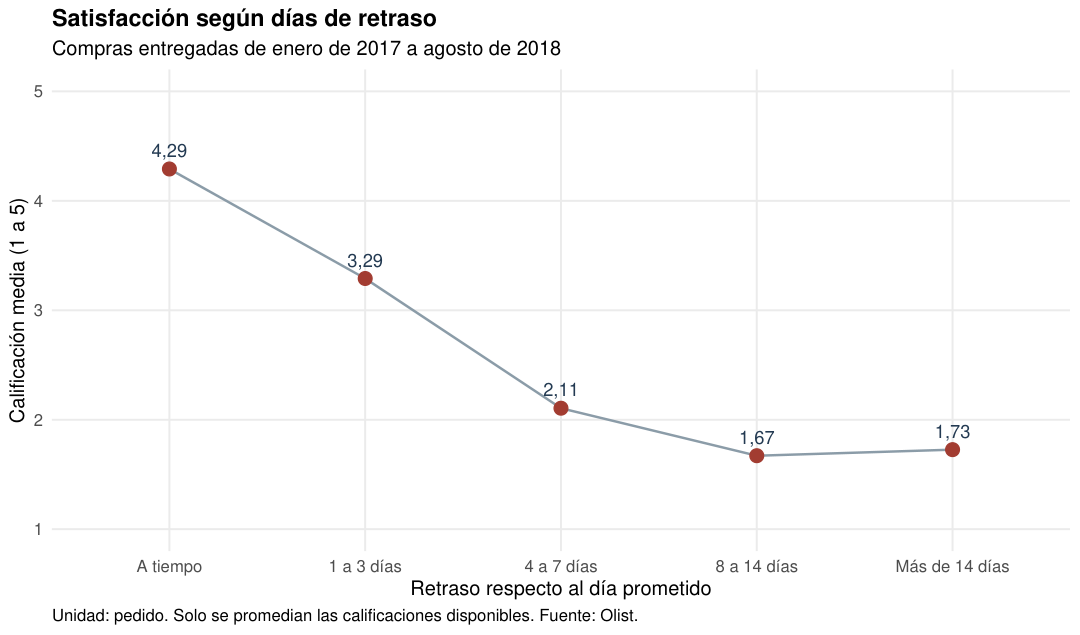

In [9]:
grafico_retraso <- ggplot(resumen_retraso, aes(x = tramo_retraso, y = nota_media, group = 1)) +
  geom_line(color = "#8C9CA8", linewidth = 0.7) +
  geom_point(color = "#A33D32", size = 3.5) +
  geom_text(aes(label = numero(nota_media, 2)), vjust = -0.9, size = 4, color = "#243B53") +
  scale_y_continuous(limits = c(1, 5), breaks = 1:5) +
  labs(title = "Satisfacción según días de retraso",
       subtitle = "Compras entregadas de enero de 2017 a agosto de 2018",
       x = "Retraso respecto al día prometido", y = "Calificación media (1 a 5)",
       caption = "Unidad: pedido. Solo se promedian las calificaciones disponibles. Fuente: Olist.") +
  theme(panel.grid.minor = element_blank(), plot.title = element_text(face = "bold"),
        axis.text.x = element_text(size = 10), plot.caption = element_text(hjust = 0))
print(grafico_retraso)


## 9. Gráfico de calificaciones bajas según flete relativo

El flete relativo compara el costo de envío con el valor de los productos del pedido.
Las barras muestran el porcentaje de pedidos con calificación media menor o igual que 2 dentro de cada tramo.
La escala parte de cero para que las diferencias pequeñas mantengan su proporción visual.


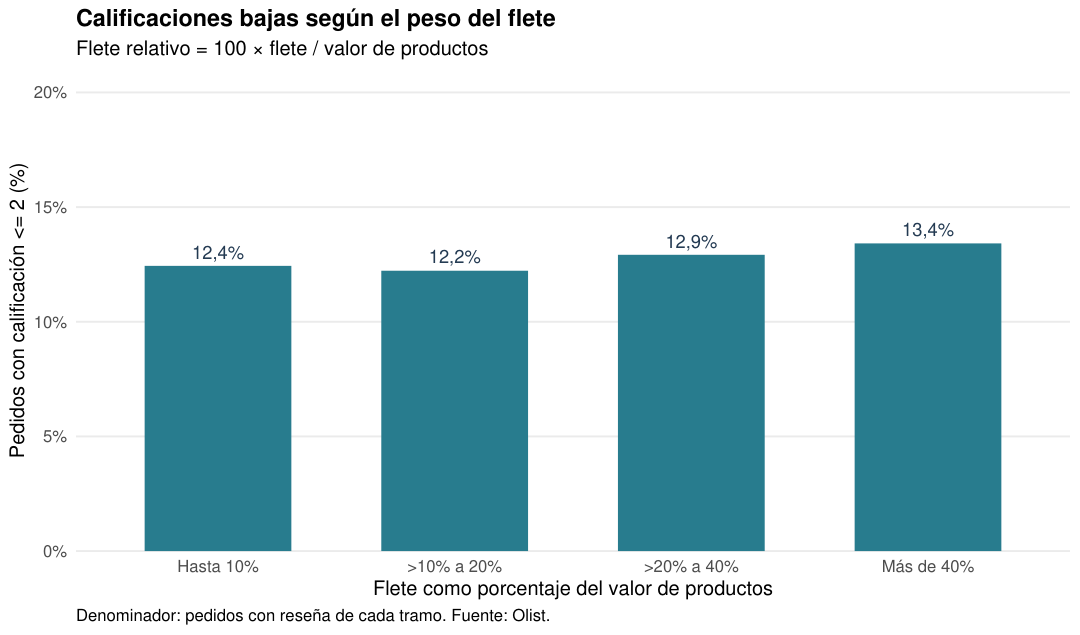

In [10]:
grafico_flete <- ggplot(resumen_flete, aes(x = tramo_flete, y = bajas_pct)) +
  geom_col(fill = "#287D8E", width = 0.62) +
  geom_text(aes(label = paste0(numero(bajas_pct, 1), "%")), vjust = -0.55, size = 4, color = "#243B53") +
  scale_y_continuous(limits = c(0, max(20, ceiling(max(resumen_flete$bajas_pct, na.rm = TRUE) / 10) * 10)),
                     labels = function(x) paste0(x, "%"), expand = expansion(mult = c(0, 0.05))) +
  labs(title = "Calificaciones bajas según el peso del flete",
       subtitle = "Flete relativo = 100 × flete / valor de productos",
       x = "Flete como porcentaje del valor de productos", y = "Pedidos con calificación <= 2 (%)",
       caption = "Denominador: pedidos con reseña de cada tramo. Fuente: Olist.") +
  theme(panel.grid.minor = element_blank(), panel.grid.major.x = element_blank(),
        plot.title = element_text(face = "bold"), axis.text.x = element_text(size = 10),
        plot.caption = element_text(hjust = 0))
print(grafico_flete)


## 10. Comprobación con pedidos que tienen una sola reseña

La regla principal promedia las reseñas de cada pedido, como en Pregunta1.
Repetimos las correlaciones sobre pedidos con una sola reseña para comprobar si el resultado depende
de los casos con varias evaluaciones. Esta es una comparación de sensibilidad; no sustituye la cohorte principal.


In [11]:
base_una_resena <- base_analisis %>% filter(n_reviews == 1)
sensibilidad <- bind_rows(purrr::map(variables, ~ calcular_correlacion(base_una_resena, .x))) %>%
  select(variable, pares_una_resena = pares, rho_una_resena = rho) %>%
  left_join(correlaciones %>% select(variable, rho_todas = rho), by = "variable") %>%
  mutate(diferencia_rho = rho_una_resena - rho_todas,
         across(starts_with("rho_"), ~ round(.x, 4)), diferencia_rho = round(diferencia_rho, 4))
print(as.data.frame(sensibilidad), row.names = FALSE)


        variable pares_una_resena rho_una_resena rho_todas diferencia_rho
    dias_entrega            95037        -0.2345   -0.2347         0.0002
    dias_retraso            95037        -0.3149   -0.3149        -0.0001
       flete_pct            95037        -0.0309   -0.0308        -0.0001
 valor_productos            95037        -0.0290   -0.0293         0.0003


## 11. Lectura de negocio y acciones

Las frases siguientes se generan desde los resultados. Para la exposición se debe distinguir el hecho observado,
su interpretación y la acción propuesta.


In [12]:
a_tiempo <- resumen_entrega %>% filter(tipo_entrega == "A tiempo")
tardias <- resumen_entrega %>% filter(tipo_entrega == "Tardía")
rho_retraso <- correlaciones$rho[correlaciones$variable == "dias_retraso"]
rho_flete <- correlaciones$rho[correlaciones$variable == "flete_pct"]
rho_valor <- correlaciones$rho[correlaciones$variable == "valor_productos"]

cat("HECHOS OBSERVADOS\n")
cat("1. Entre pedidos con reseña, las calificaciones bajas representan ", numero(a_tiempo$bajas_pct),
    "% de las entregas a tiempo y ", numero(tardias$bajas_pct), "% de las tardías. Diferencia: ",
    numero(tardias$bajas_pct - a_tiempo$bajas_pct), " puntos porcentuales.\n", sep = "")
cat("2. La correlación de retraso y calificación es rho = ", numero(rho_retraso, 3),
    "; para flete relativo es ", numero(rho_flete, 3), " y para valor de productos es ",
    numero(rho_valor, 3), ".\n", sep = "")
cat("3. La cohorte contiene ", numero(nrow(base_analisis), 0), " pedidos; ",
    numero(sum(!is.na(base_analisis$satisfaccion)), 0), " tienen calificación.\n\n", sep = "")
cat("INTERPRETACIÓN\n")
cat("En esta cohorte, el retraso presenta una asociación negativa con la calificación más marcada que el flete relativo o el valor de compra.\n")
cat("Los coeficientes del flete y del valor son cercanos a cero; un p valor pequeño no vuelve grande su importancia práctica.\n\n")
cat("ACCIONES PROPUESTAS\n")
cat("Revisar el cumplimiento de la promesa de entrega y estudiar los pedidos con retraso y calificación baja.\n")
cat("Usar el peso del flete como señal complementaria y contrastarlo por categoría o región en el análisis del equipo.\n")
cat("Estas asociaciones no prueban causalidad. Pueden intervenir diferencias de producto, región, vendedor o expectativa del cliente.\n")


HECHOS OBSERVADOS
1. Entre pedidos con reseña, las calificaciones bajas representan 9,2% de las entregas a tiempo y 62,4% de las tardías. Diferencia: 53,1 puntos porcentuales.
2. La correlación de retraso y calificación es rho = -0,315; para flete relativo es -0,031 y para valor de productos es -0,029.
3. La cohorte contiene 96.203 pedidos; 95.560 tienen calificación.

INTERPRETACIÓN
En esta cohorte, el retraso presenta una asociación negativa con la calificación más marcada que el flete relativo o el valor de compra.
Los coeficientes del flete y del valor son cercanos a cero; un p valor pequeño no vuelve grande su importancia práctica.

ACCIONES PROPUESTAS
Revisar el cumplimiento de la promesa de entrega y estudiar los pedidos con retraso y calificación baja.
Usar el peso del flete como señal complementaria y contrastarlo por categoría o región en el análisis del equipo.
Estas asociaciones no prueban causalidad. Pueden intervenir diferencias de producto, región, vendedor o expectativa

## 12. Exportación y reproducibilidad

Se guardan los resúmenes, la trazabilidad de filtros, las correlaciones y los dos gráficos en PDF.
La base completa se conserva en memoria para que el equipo pueda integrarla con las otras preguntas.
Los resultados se vuelven a generar en cada ejecución.


In [13]:
raiz_proyecto <- if (dir.exists("../data/olist")) ".." else "."
ruta_salidas <- file.path(raiz_proyecto, "salidas", "pregunta3_gustavo")
dir.create(ruta_salidas, recursive = TRUE, showWarnings = FALSE)
exportaciones <- list(
  diagnostico = diagnostico, reglas_preparacion = reglas_preparacion, filtros = filtros,
  comparacion_entregas = resumen_entrega, tramos_retraso = resumen_retraso,
  tramos_flete = resumen_flete, correlaciones = correlaciones, sensibilidad = sensibilidad
)
purrr::iwalk(exportaciones, ~ readr::write_csv(.x, file.path(ruta_salidas, paste0(.y, ".csv")), na = ""))
ggsave(file.path(ruta_salidas, "01_satisfaccion_retraso.pdf"), grafico_retraso,
       width = 9, height = 5.3, device = "pdf", useKerning = FALSE)
ggsave(file.path(ruta_salidas, "02_calificaciones_flete.pdf"), grafico_flete,
       width = 9, height = 5.3, device = "pdf", useKerning = FALSE)
cat("Tablas y gráficos guardados en salidas/pregunta3_gustavo/.\n")
cat("\nVersiones utilizadas:\n")
print(data.frame(paquete = paquetes, version = vapply(paquetes, function(p) as.character(packageVersion(p)), character(1))),
      row.names = FALSE)
print(R.version.string)


Tablas y gráficos guardados en salidas/pregunta3_gustavo/.

Versiones utilizadas:
   paquete version
     readr   2.2.0
     dplyr   1.2.1
     tidyr   1.3.2
   stringr   1.6.0
 lubridate   1.9.5
   ggplot2   4.0.3
     purrr   1.2.2
    scales   1.4.0
[1] "R version 4.6.0 (2026-04-24)"


## Fuentes y relación con el trabajo del equipo

- **Datos:** Olist. [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce).
  Archivo original proporcionado para el caso. Se conserva la moneda original; no se hace conversión monetaria.
- **Licencia de los datos:** [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/).
  Las tablas derivadas aplican las transformaciones descritas en este notebook.
- **Criterio compartido:** [Pregunta1 del equipo](https://github.com/santiago-1710/Caso-Integrador-Final/blob/97c846072c9e51ce4e99ad3880b6b3b4aa88754c/notebooks/Pregunta1.ipynb).
  Se mantiene la ventana de compra y la agregación de reseñas por promedio.
- **Referencia técnica:** R Core Team. [cor.test](https://stat.ethz.ch/R-manual/R-devel/library/stats/html/cor.test.html).
  Documentación de correlación de Spearman y tratamiento aproximado del contraste.

La cola final de prioridades se desarrollará en la pregunta correspondiente, usando los indicadores y las definiciones
que acuerde el equipo. Este avance responde a la tercera pregunta en R.
